# Example: automatic detection of droplets in a large image

A simulated fluorescence image of 1000 × 1000 px with 300 droplets of radius
5 to 14 px, placed at random. A third of them are elongated, and droplets can
overlap: overlapping droplets add up, and the sum is blurred like a
microscope image. They lie on a background of 0.15 that varies smoothly by up
to ±0.1, like uneven illumination, with noise and 8-bit quantization. Since
the image is simulated, every droplet's true footprint is known, and the
figure counts a droplet as found when a segment covers it with an
intersection over union above 0.5.

[segmenting_droplets.ipynb](segmenting_droplets.ipynb) explains the steps and
their parameters.

In [1]:
import time

import numpy as np

import dropseg
from dropseg import Parameters, segment_image
from dropseg.plots import plot_large_scene
from dropseg.simulate import camera, count_found, droplet_image, sample_droplets, true_labels

WORKERS = 1   # processes for the tiles; e.g. 4 is about 3× faster, with the same results

In [2]:
SHAPE, N_DROPLETS, SEED = (1000, 1000), 300, 0

droplets = sample_droplets(np.random.default_rng(SEED), SHAPE, n_droplets=N_DROPLETS)
image = camera(droplet_image(droplets, SHAPE, seed=SEED, background_variation=0.1))
truth = true_labels(droplets, SHAPE)
print(f"background from {np.percentile(image[truth == 0], 1):.2f} to {np.percentile(image[truth == 0], 99):.2f}")

background from 0.10 to 0.22


## Parameters

The droplets here are large (10 to 28 px across), so there is no need to
upsample. Four parameters differ from the defaults, which suit small droplets
on a dark background:

- `min_level=0.3`: the background reaches about 0.25, and the outlines must lie
  above it.
- `min_bar_length=0.1`: the droplets rise at least 0.4 above the background,
  and the noise makes peaks of only about 0.05.
- `split_level=0.8`: overlapping droplets add up, so the saddle between two
  of them can lie high. Peaks that separate below 0.8 are separate droplets.
- `lobe_waist=0.85`: two large overlapping domes leave only a shallow waist
  in their joint outline, so outlines are split at wider waists than the
  default 0.75.

The image is larger than 600 × 600 px, so it is segmented in tiles, in
parallel if `WORKERS > 1`. Each tile's margin must be larger than a droplet: `tile_margin=32`.

In [3]:
parameters = Parameters(min_bar_length=0.1, split_level=0.8, min_level=0.3, lobe_waist=0.85)

start = time.perf_counter()
segmentation = segment_image(image, parameters, WORKERS, tile_size=128, tile_margin=32)
elapsed = time.perf_counter() - start
n_found = count_found(segmentation.labels, truth)
print(f"{segmentation.n_segments} segments, {n_found} of {N_DROPLETS} droplets found in {elapsed:.0f} s (WORKERS = {WORKERS})")

268 segments, 266 of 300 droplets found in 24 s (WORKERS = 1)


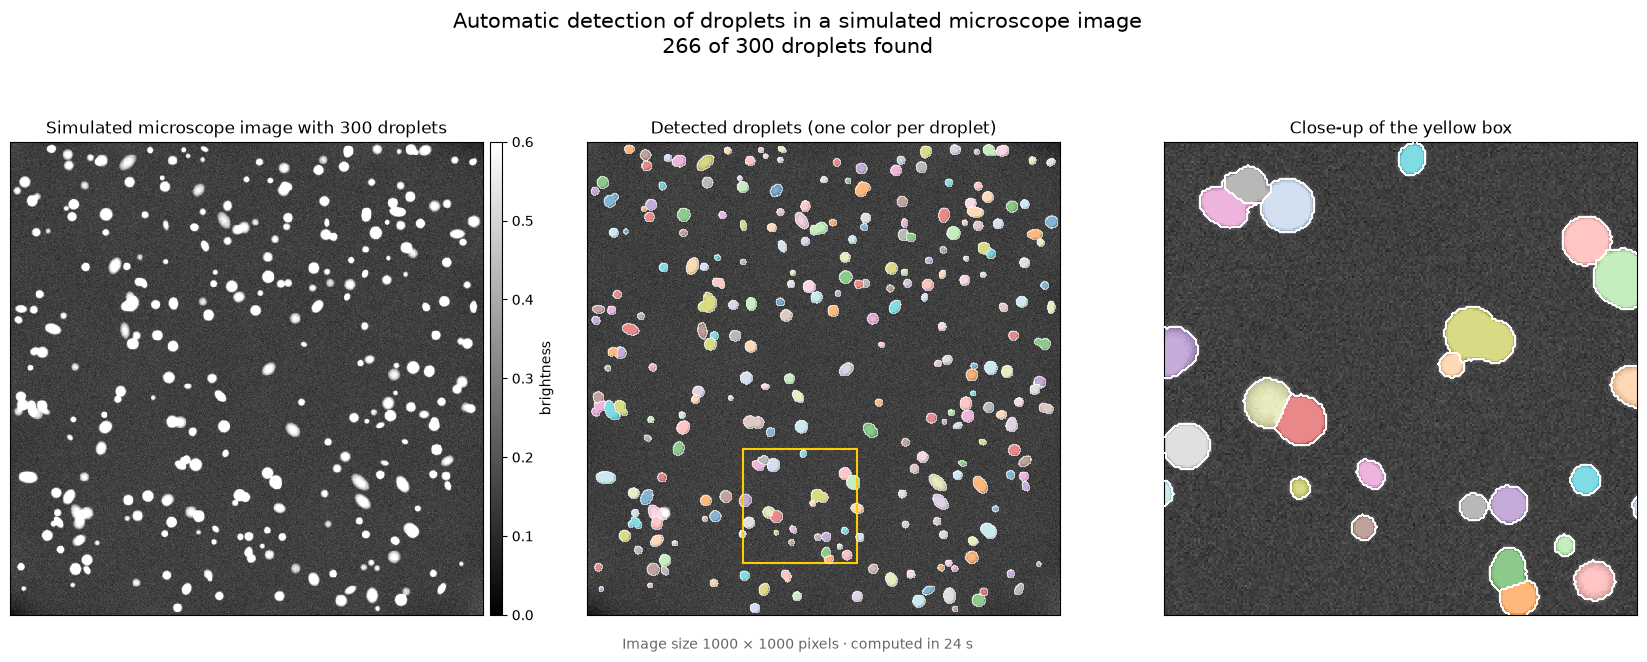

In [4]:
centers = np.array([(droplet.row, droplet.column) for droplet in droplets])
fig = plot_large_scene(image, segmentation.labels, N_DROPLETS, n_found,
                       "Automatic detection of droplets in a simulated microscope image",
                       note=f"Image size {SHAPE[0]} × {SHAPE[1]} pixels · computed in {elapsed:.0f} s",
                       vmax=0.6, centers=centers)

The close-up shows the window with the most droplets. About a third of the
droplets that are not found are mostly hidden under a brighter neighbor,
which no segmentation of the image can recover. The others are overlapping
pairs whose joint outline has almost no waist, and are merged into one
segment.